# CADT 实验结果汇总

本 Notebook 汇总所有实验结果，包括三种标准化策略的对比：
- **Sample 标准化**（`results4/`）：逐样本 Z-Score
- **Day 标准化**（`result_day_td/`）：cross_subject + 按天分组 Z-Score
- **Subject 标准化**（`result_sub_std/`）：cross_day + 按被试分组 Z-Score

## 标准化策略说明

| 名称 | 标准化方式 | 应用场景 | 结果目录 |
|------|-----------|----------|----------|
| **sample** | 逐样本 Z-Score | 所有 split_mode | `results4/` |
| **day** | 按天分组 Z-Score（跨被试） | cross_subject | `result_day_td/` |
| **subject** | 按被试分组 Z-Score（跨天） | cross_day | `result_sub_std/` |

In [16]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.rcParams['font.sans-serif'] = ['SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid')

EMOTIONS = ['inspired', 'alert', 'determined', 'attentive', 'active',
            'hostile', 'nervous', 'upset', 'afraid', 'ashamed', 'fatigue']

def parse_results_file(filepath):
    """Parse a single results.txt file."""
    with open(filepath, 'r') as f:
        content = f.read()
    result = {}
    m = re.search(r'Split Mode: (\w+)', content)
    if m: result['split_mode'] = m.group(1)
    m = re.search(r'Target Subject: (\d+)', content)
    if m: result['target_subject'] = int(m.group(1))
    else: result['target_subject'] = 'all'
    m = re.search(r'Best Epoch: (\d+)', content)
    if m: result['best_epoch'] = int(m.group(1))
    m = re.search(r'Number of Source Domains: (\d+)', content)
    if m: result['n_source_domains'] = int(m.group(1))
    metric_labels = {'mse': 'MSE', 'mae': 'MAE', 'rmse': 'RMSE',
                     'r2': 'R2', 'pearson': 'Pearson', 'spearman': 'Spearman'}
    for prefix in ['val', 'test']:
        cap = prefix.capitalize()
        for metric, label in metric_labels.items():
            pat = cap + ' ' + label + r': ([\d.-]+)'
            m = re.search(pat, content)
            if m: result[prefix + '_' + metric] = float(m.group(1))
        pat = cap + r' Avg R2 \(per-dim\): ([\d.-]+)'
        m = re.search(pat, content)
        if m: result[prefix + '_avg_r2'] = float(m.group(1))
    per_emotion = {}
    lines = content.split('\n')
    in_table = False
    for line in lines:
        if 'Per-Emotion Metrics' in line:
            in_table = True; continue
        if in_table and '------' in line: continue
        if in_table and line.strip() == '': break
        if in_table:
            parts = line.split()
            if len(parts) >= 6:
                try:
                    per_emotion[parts[0]] = {
                        'MSE': float(parts[1]), 'MAE': float(parts[2]),
                        'R2': float(parts[3]), 'Pearson': float(parts[4]),
                        'Spearman': float(parts[5])
                    }
                except ValueError: pass
    result['per_emotion'] = per_emotion
    return result

def load_all_experiments(results_dir):
    exps = []
    for entry in sorted(os.listdir(results_dir)):
        ep = os.path.join(results_dir, entry)
        if os.path.isdir(ep) and 'emotion' in entry:
            rf = os.path.join(ep, 'results.txt')
            if os.path.exists(rf):
                r = parse_results_file(rf)
                r['directory'] = entry
                exps.append(r)
    return exps

def format_ms(mean, std, decimals=4):
    return f"{mean:.{decimals}f} ± {std:.{decimals}f}"

def agg_per_emotion(exps, split_mode=None, target_subject=None):
    filt = exps
    if split_mode is not None:
        filt = [e for e in filt if e.get('split_mode') == split_mode]
    if target_subject is not None:
        filt = [e for e in filt if e.get('target_subject') == target_subject]
    if not filt:
        return None
    rows = []
    for em in EMOTIONS:
        mse_v, mae_v, r2_v, pear_v, spear_v = [], [], [], [], []
        for e in filt:
            pe = e.get('per_emotion', {})
            if em in pe:
                mse_v.append(pe[em]['MSE'])
                mae_v.append(pe[em]['MAE'])
                r2_v.append(pe[em]['R2'])
                pear_v.append(pe[em]['Pearson'])
                spear_v.append(pe[em]['Spearman'])
        if mse_v:
            rows.append({
                'Emotion': em, 'n_seeds': len(mse_v),
                'MSE_mean': np.mean(mse_v), 'MSE_std': np.std(mse_v, ddof=1) if len(mse_v)>1 else 0,
                'MAE_mean': np.mean(mae_v), 'MAE_std': np.std(mae_v, ddof=1) if len(mae_v)>1 else 0,
                'R2_mean': np.mean(r2_v), 'R2_std': np.std(r2_v, ddof=1) if len(r2_v)>1 else 0,
                'Pearson_mean': np.mean(pear_v), 'Pearson_std': np.std(pear_v, ddof=1) if len(pear_v)>1 else 0,
                'Spearman_mean': np.mean(spear_v), 'Spearman_std': np.std(spear_v, ddof=1) if len(spear_v)>1 else 0,
            })
    d = pd.DataFrame(rows)
    if len(d) > 0:
        d['MSE (mean±std)'] = d.apply(lambda r: format_ms(r['MSE_mean'], r['MSE_std']), axis=1)
        d['MAE (mean±std)'] = d.apply(lambda r: format_ms(r['MAE_mean'], r['MAE_std']), axis=1)
        d['R2 (mean±std)'] = d.apply(lambda r: format_ms(r['R2_mean'], r['R2_std']), axis=1)
        d['Pearson (mean±std)'] = d.apply(lambda r: format_ms(r['Pearson_mean'], r['Pearson_std']), axis=1)
        d['Spearman (mean±std)'] = d.apply(lambda r: format_ms(r['Spearman_mean'], r['Spearman_std']), axis=1)
    return d

def agg_overall(exps, label):
    row = {'label': label, 'n_seeds': len(exps)}
    for m in ['test_mse','test_mae','test_r2','test_avg_r2','test_pearson','test_spearman',
              'val_mse','val_mae','val_r2','val_avg_r2','val_pearson','val_spearman']:
        vals = [e[m] for e in exps if m in e]
        if vals:
            row[m+'_mean'] = np.mean(vals)
            row[m+'_std'] = np.std(vals, ddof=1) if len(vals)>1 else 0
            row[m+'_ms'] = format_ms(np.mean(vals), np.std(vals, ddof=1) if len(vals)>1 else 0)
    return row

results4_exps = load_all_experiments('/vePFS-0x0d/home/zjm/results4/')
day_td_exps = load_all_experiments('/root/zjm/cadt/result_day_td')
sub_std_exps = load_all_experiments('/root/zjm/cadt/result_sub_std')

for e in results4_exps: e['norm_mode'] = 'sample'
for e in day_td_exps: e['norm_mode'] = 'day'
for e in sub_std_exps: e['norm_mode'] = 'subject'

all_exps = results4_exps + day_td_exps + sub_std_exps
df = pd.DataFrame([{k: v for k, v in e.items() if k != 'per_emotion'} for e in all_exps])

print(f"Total experiments: {len(all_exps)}")
print(f"  results4 (sample): {len(results4_exps)}")
print(f"  result_day_td (day): {len(day_td_exps)}")
print(f"  result_sub_std (subject): {len(sub_std_exps)}")
print()
print("By split_mode x norm_mode:")
print(df.groupby(['split_mode', 'norm_mode']).size())

Total experiments: 105
  results4 (sample): 90
  result_day_td (day): 10
  result_sub_std (subject): 5

By split_mode x norm_mode:
split_mode          norm_mode
cross_day           day           5
                    sample       80
                    subject       5
cross_subject       day           5
                    sample        5
within_subject_day  sample        5
dtype: int64


## 1. Overall Performance Comparison

Two R2 variants are reported:
- **Overall R2 (Test R2)**: Aggregated R2 over all samples x all emotion dimensions
- **Per-Emotion Avg R2 (Test Avg R2)**: R2 computed per emotion dimension, then averaged across 11 emotions

### 1.1 Cross-Subject: Sample vs Day Normalization


In [17]:
cs_sample = [e for e in results4_exps if e['split_mode']=='cross_subject']
cs_day = day_td_exps  # all are cross_subject + day norm

overall_rows = []
overall_rows.append(agg_overall(cs_sample, 'Cross-Subject (Sample)'))
overall_rows.append(agg_overall(cs_day, 'Cross-Subject (Day)'))
overall_rows.append(agg_overall([e for e in results4_exps if e['split_mode']=='cross_day'], 'Cross-Day (Sample)'))
overall_rows.append(agg_overall(sub_std_exps, 'Cross-Day (Subject)'))
overall_rows.append(agg_overall([e for e in results4_exps if e['split_mode']=='within_subject_day'], 'Within-Subject-Day (Sample)'))

overall_df = pd.DataFrame(overall_rows)

# Full comparison table (includes both R2 variants)
cols_all = ['label','n_seeds','test_mse_ms','test_mae_ms','test_r2_ms','test_avg_r2_ms','test_pearson_ms','test_spearman_ms']
print('Test Set Overall Results Comparison (all metrics):')
print(overall_df[cols_all].to_string(index=False))
print()

# Focused R2 comparison: Overall R2 vs Per-Emotion Avg R2
print('R2 Comparison (Overall R2 vs Per-Emotion Avg R2):')
r2_comp = overall_df[['label','n_seeds','test_r2_ms','test_avg_r2_ms']].copy()
r2_comp['delta (AvgR2 - R2)'] = overall_df['test_avg_r2_mean'] - overall_df['test_r2_mean']
print(r2_comp.to_string(index=False))
print()

# Per normalization delta analysis
print('Per-Normalization Delta R2 Analysis:')
print('  Cross-Subject (Day - Sample):')
cs_s = overall_df[overall_df['label']=='Cross-Subject (Sample)'].iloc[0]
cs_d = overall_df[overall_df['label']=='Cross-Subject (Day)'].iloc[0]
print(f"    Delta Overall R2      = {cs_d['test_r2_mean']-cs_s['test_r2_mean']:+.4f}")
print(f"    Delta Per-Emotion Avg = {cs_d['test_avg_r2_mean']-cs_s['test_avg_r2_mean']:+.4f}")
print('  Cross-Day (Subject - Sample):')
cd_s = overall_df[overall_df['label']=='Cross-Day (Sample)'].iloc[0]
cd_u = overall_df[overall_df['label']=='Cross-Day (Subject)'].iloc[0]
print(f"    Delta Overall R2      = {cd_u['test_r2_mean']-cd_s['test_r2_mean']:+.4f}")
print(f"    Delta Per-Emotion Avg = {cd_u['test_avg_r2_mean']-cd_s['test_avg_r2_mean']:+.4f}")


Test Set Overall Results Comparison (all metrics):
                      label  n_seeds     test_mse_ms     test_mae_ms      test_r2_ms   test_avg_r2_ms test_pearson_ms test_spearman_ms
     Cross-Subject (Sample)        5 0.6998 ± 0.0195 0.6899 ± 0.0126 0.1080 ± 0.0249 -0.1763 ± 0.0376 0.0364 ± 0.0418  0.0393 ± 0.0463
        Cross-Subject (Day)       10 0.7766 ± 0.0703 0.7097 ± 0.0160 0.1353 ± 0.0497 -0.1057 ± 0.1012 0.0328 ± 0.0816  0.0242 ± 0.0892
         Cross-Day (Sample)       80 0.7307 ± 0.2933 0.6262 ± 0.1602 0.1688 ± 0.2046 -0.3205 ± 0.2239 0.0244 ± 0.1098  0.0253 ± 0.1127
        Cross-Day (Subject)        5 0.8424 ± 0.0032 0.7241 ± 0.0022 0.1768 ± 0.0031 -0.0149 ± 0.0037 0.0764 ± 0.0826  0.1057 ± 0.0724
Within-Subject-Day (Sample)        5 0.8919 ± 0.0136 0.7380 ± 0.0083 0.1801 ± 0.0125 -0.0358 ± 0.0167 0.1670 ± 0.0470  0.1946 ± 0.0483

R2 Comparison (Overall R2 vs Per-Emotion Avg R2):
                      label  n_seeds      test_r2_ms   test_avg_r2_ms  delta (AvgR2 - R2

### 1.2 Cross-Subject 逐情绪 R²: Sample vs Day

In [18]:
cs_samp_df = agg_per_emotion(cs_sample, 'cross_subject', 'all')
cs_day_df = agg_per_emotion(cs_day, 'cross_subject', 'all')

if cs_samp_df is not None and cs_day_df is not None:
    comp = pd.merge(
        cs_samp_df[['Emotion','R2_mean','R2_std']],
        cs_day_df[['Emotion','R2_mean','R2_std']],
        on='Emotion', suffixes=('_sample','_day'))
    comp['delta_R2'] = comp['R2_mean_day'] - comp['R2_mean_sample']
    comp['R2_sample_ms'] = comp.apply(lambda r: format_ms(r['R2_mean_sample'], r['R2_std_sample']), axis=1)
    comp['R2_day_ms'] = comp.apply(lambda r: format_ms(r['R2_mean_day'], r['R2_std_day']), axis=1)
    print('Cross-Subject: Sample vs Day Normalization Per-Emotion R2:')
    print(comp[['Emotion','R2_sample_ms','R2_day_ms','delta_R2']].to_string(index=False))
else:
    print('Missing data')

Cross-Subject: Sample vs Day Normalization Per-Emotion R2:
   Emotion     R2_sample_ms        R2_day_ms  delta_R2
  inspired -0.4084 ± 0.2442 -0.5695 ± 0.1116  -0.16104
     alert -0.1296 ± 0.0882 -0.1963 ± 0.0540  -0.06672
determined -0.5695 ± 0.2473 -0.7440 ± 0.1209  -0.17456
 attentive -0.0985 ± 0.0559 -0.1241 ± 0.0521  -0.02558
    active -0.1176 ± 0.0421 -0.1310 ± 0.0479  -0.01344
   hostile -0.0885 ± 0.0599 -0.0774 ± 0.0298   0.01108
   nervous -0.0849 ± 0.0393 -0.1026 ± 0.0188  -0.01772
     upset -0.0161 ± 0.0325 -0.0047 ± 0.0079   0.01136
    afraid -0.1612 ± 0.1050 -0.2157 ± 0.0448  -0.05454
   ashamed -0.0103 ± 0.0180 -0.0092 ± 0.0101   0.00116
   fatigue -0.0194 ± 0.0372 -0.0023 ± 0.0047   0.01708


### 1.3 Cross-Day 逐情绪 R²: Sample vs Subject

In [19]:
cd_sample = [e for e in results4_exps if e['split_mode']=='cross_day']
cd_samp_df = agg_per_emotion(cd_sample, 'cross_day')
cd_sub_df = agg_per_emotion(sub_std_exps, 'cross_day')

if cd_samp_df is not None and cd_sub_df is not None:
    comp = pd.merge(
        cd_samp_df[['Emotion','R2_mean','R2_std']],
        cd_sub_df[['Emotion','R2_mean','R2_std']],
        on='Emotion', suffixes=('_sample','_subject'))
    comp['delta_R2'] = comp['R2_mean_subject'] - comp['R2_mean_sample']
    comp['R2_sample_ms'] = comp.apply(lambda r: format_ms(r['R2_mean_sample'], r['R2_std_sample']), axis=1)
    comp['R2_subject_ms'] = comp.apply(lambda r: format_ms(r['R2_mean_subject'], r['R2_std_subject']), axis=1)
    print('Cross-Day: Sample vs Subject Normalization Per-Emotion R2:')
    print(comp[['Emotion','R2_sample_ms','R2_subject_ms','delta_R2']].to_string(index=False))
else:
    print('Missing data')

Cross-Day: Sample vs Subject Normalization Per-Emotion R2:
   Emotion     R2_sample_ms    R2_subject_ms  delta_R2
  inspired -0.2601 ± 0.4849 -0.0469 ± 0.0064  0.213250
     alert -0.2563 ± 0.3188 -0.0132 ± 0.0066  0.243137
determined -0.3774 ± 0.6876 -0.0639 ± 0.0143  0.313567
 attentive -0.1716 ± 0.2804 -0.0049 ± 0.0104  0.166669
    active -0.3936 ± 0.8427 -0.0111 ± 0.0051  0.382451
   hostile -0.1882 ± 0.2347 -0.0125 ± 0.0075  0.175640
   nervous -0.1801 ± 0.1759 -0.0130 ± 0.0072  0.167161
     upset -0.1701 ± 0.1965 -0.0051 ± 0.0058  0.165005
    afraid -0.2900 ± 0.4777 -0.0314 ± 0.0067  0.258605
   ashamed -0.1648 ± 0.1876 -0.0207 ± 0.0113  0.144165
   fatigue -0.2415 ± 0.2731 -0.0204 ± 0.0077  0.221066


### 1.4 各标准化策略逐情绪完整结果

In [20]:
wsd_df = agg_per_emotion([e for e in results4_exps if e['split_mode']=='within_subject_day'], 'within_subject_day', 'all')

for label, dt in [
    ('Cross-Subject (Sample)', cs_samp_df),
    ('Cross-Subject (Day)', cs_day_df),
    ('Cross-Day (Sample)', cd_samp_df),
    ('Cross-Day (Subject)', cd_sub_df),
    ('Within-Subject-Day (Sample)', wsd_df),
]:
    if dt is not None and len(dt) > 0:
        print(f'\n--- {label} ---')
        cols = ['Emotion','n_seeds','MSE (mean±std)','MAE (mean±std)','R2 (mean±std)','Pearson (mean±std)','Spearman (mean±std)']
        print(dt[cols].to_string(index=False))


--- Cross-Subject (Sample) ---
   Emotion  n_seeds  MSE (mean±std)  MAE (mean±std)    R2 (mean±std) Pearson (mean±std) Spearman (mean±std)
  inspired        5 0.9235 ± 0.0683 0.8348 ± 0.0299 -0.4084 ± 0.2442    0.1181 ± 0.0352     0.1055 ± 0.0417
     alert        5 0.5811 ± 0.1385 0.6833 ± 0.0433 -0.1296 ± 0.0882    0.0773 ± 0.1130     0.0797 ± 0.1307
determined        5 0.9382 ± 0.2566 0.8214 ± 0.0673 -0.5695 ± 0.2473    0.0803 ± 0.0846     0.1177 ± 0.0723
 attentive        5 1.3022 ± 0.1152 0.9158 ± 0.0554 -0.0985 ± 0.0559    0.0128 ± 0.0205     0.0029 ± 0.0258
    active        5 0.9864 ± 0.1613 0.8411 ± 0.0542 -0.1176 ± 0.0421    0.0157 ± 0.1152     0.0293 ± 0.1252
   hostile        5 0.4081 ± 0.1739 0.4960 ± 0.0747 -0.0885 ± 0.0599   -0.0102 ± 0.0986    -0.0181 ± 0.1456
   nervous        5 0.6137 ± 0.1214 0.6738 ± 0.0371 -0.0849 ± 0.0393    0.0502 ± 0.0974     0.0432 ± 0.1148
     upset        5 0.9938 ± 0.1373 0.8213 ± 0.0264 -0.0161 ± 0.0325    0.0296 ± 0.0749     0.0407 ± 0.0

## 2. Visualization

### 2.1 Overall Performance Bar Charts (both R2 variants)


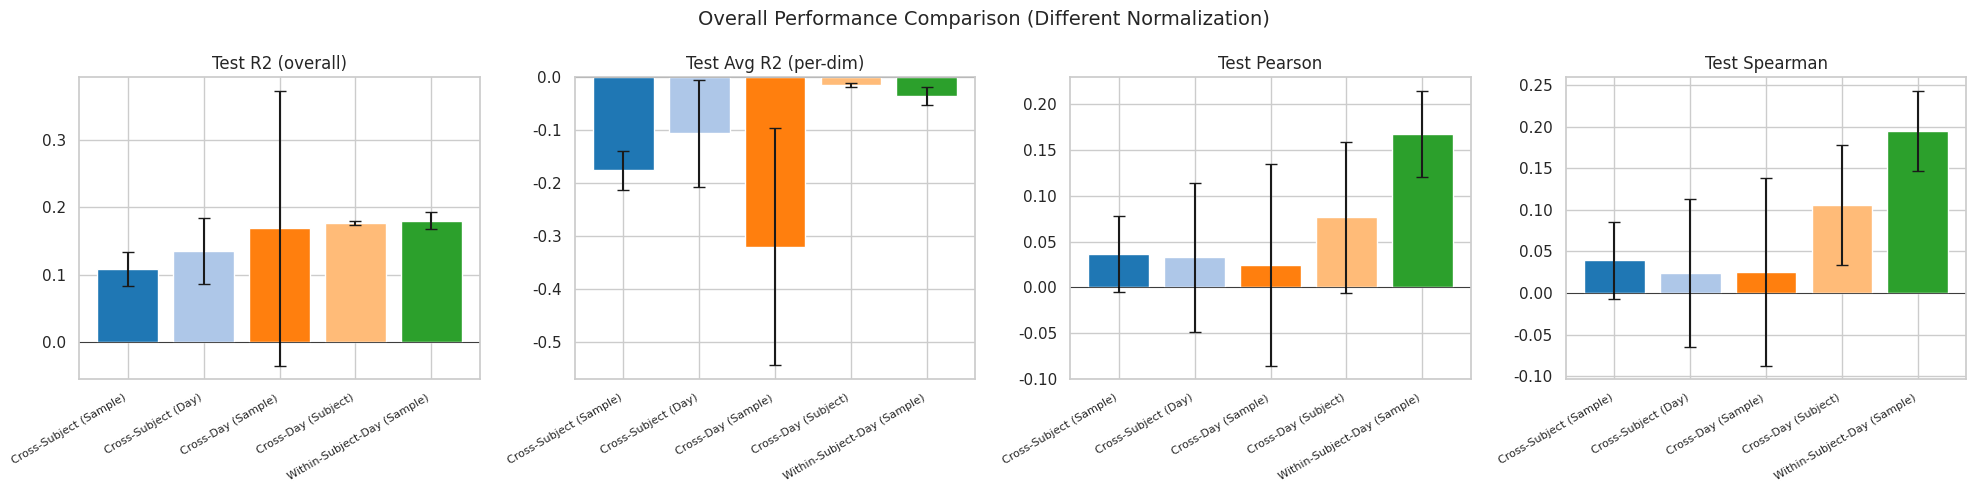

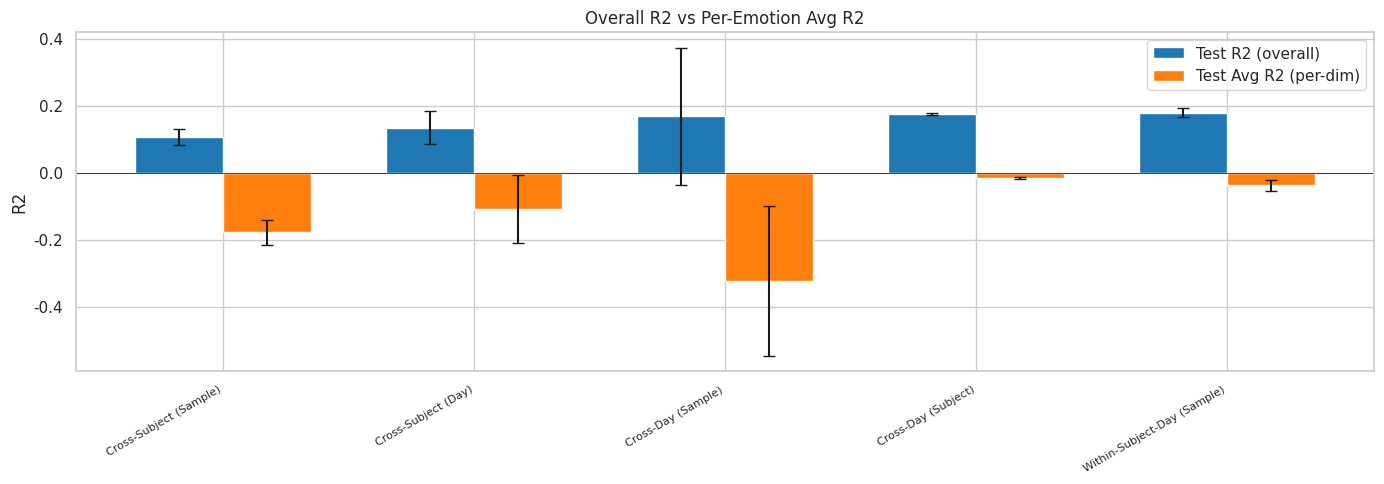

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
labels = overall_df['label'].tolist()
x = np.arange(len(labels))
colors = ['#1f77b4','#aec7e8','#ff7f0e','#ffbb78','#2ca02c']

for ax, (metric, title) in zip(axes, [
    ('test_r2', 'Test R2 (overall)'),
    ('test_avg_r2', 'Test Avg R2 (per-dim)'),
    ('test_pearson', 'Test Pearson'),
    ('test_spearman', 'Test Spearman')
]):
    means = overall_df[metric+'_mean'].values
    stds = overall_df[metric+'_std'].values
    bars = ax.bar(x, means, yerr=stds, capsize=4, color=colors[:len(x)])
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=8, rotation=30, ha='right')
    ax.set_title(title)
    ax.axhline(y=0, color='black', linewidth=0.5)
plt.suptitle('Overall Performance Comparison (Different Normalization)', fontsize=14)
plt.tight_layout()
plt.show()

# Grouped bar chart: R2 vs Avg R2 side-by-side
fig, ax = plt.subplots(figsize=(14, 5))
w = 0.35
r2_means = overall_df['test_r2_mean'].values
r2_stds  = overall_df['test_r2_std'].values
avg_means = overall_df['test_avg_r2_mean'].values
avg_stds  = overall_df['test_avg_r2_std'].values
ax.bar(x - w/2, r2_means, w, yerr=r2_stds, capsize=4, label='Test R2 (overall)', color='#1f77b4')
ax.bar(x + w/2, avg_means, w, yerr=avg_stds, capsize=4, label='Test Avg R2 (per-dim)', color='#ff7f0e')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=8, rotation=30, ha='right')
ax.set_ylabel('R2')
ax.set_title('Overall R2 vs Per-Emotion Avg R2')
ax.axhline(y=0, color='black', linewidth=0.5)
ax.legend()
plt.tight_layout()
plt.show()


### 2.2 Cross-Subject 逐情绪 R²: Sample vs Day

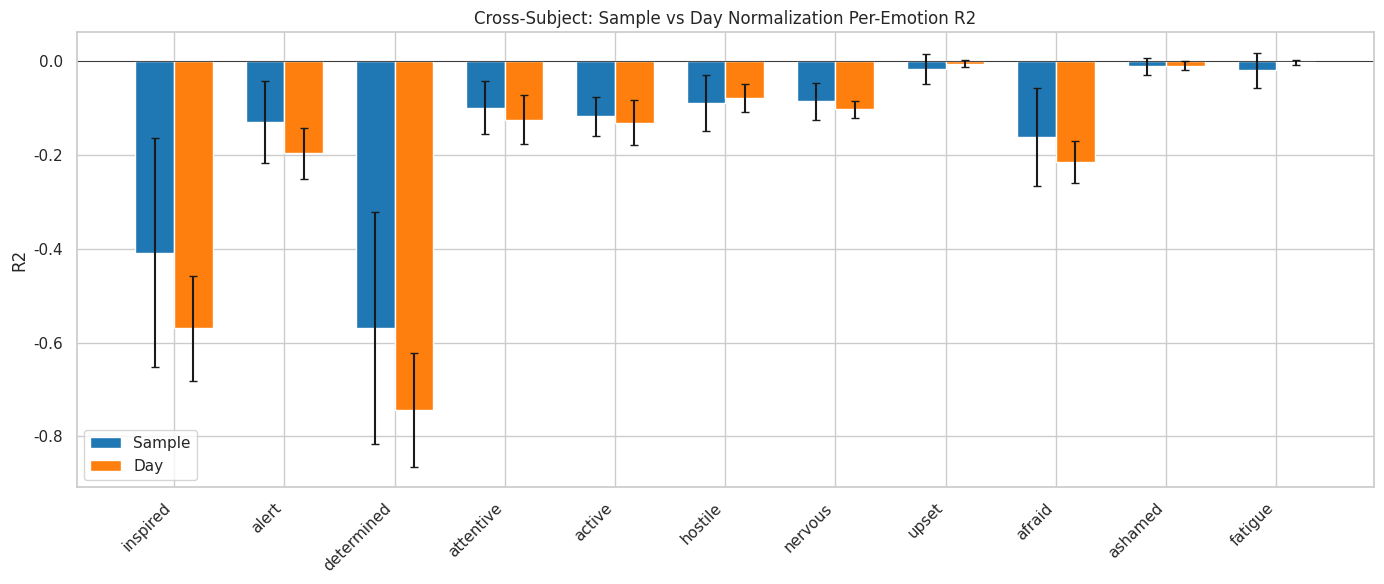

In [22]:
if cs_samp_df is not None and cs_day_df is not None:
    fig, ax = plt.subplots(figsize=(14, 6))
    x = np.arange(len(EMOTIONS))
    w = 0.35
    s_means = cs_samp_df.set_index('Emotion')['R2_mean'].reindex(EMOTIONS).values
    s_stds = cs_samp_df.set_index('Emotion')['R2_std'].reindex(EMOTIONS).values
    d_means = cs_day_df.set_index('Emotion')['R2_mean'].reindex(EMOTIONS).values
    d_stds = cs_day_df.set_index('Emotion')['R2_std'].reindex(EMOTIONS).values

    ax.bar(x - w/2, s_means, w, yerr=s_stds, label='Sample', color='#1f77b4', capsize=3)
    ax.bar(x + w/2, d_means, w, yerr=d_stds, label='Day', color='#ff7f0e', capsize=3)
    ax.set_xticks(x)
    ax.set_xticklabels(EMOTIONS, rotation=45, ha='right')
    ax.set_ylabel('R2')
    ax.set_title('Cross-Subject: Sample vs Day Normalization Per-Emotion R2')
    ax.axhline(y=0, color='black', linewidth=0.5)
    ax.legend()
    plt.tight_layout()
    plt.show()

### 2.3 Cross-Day 逐情绪 R²: Sample vs Subject

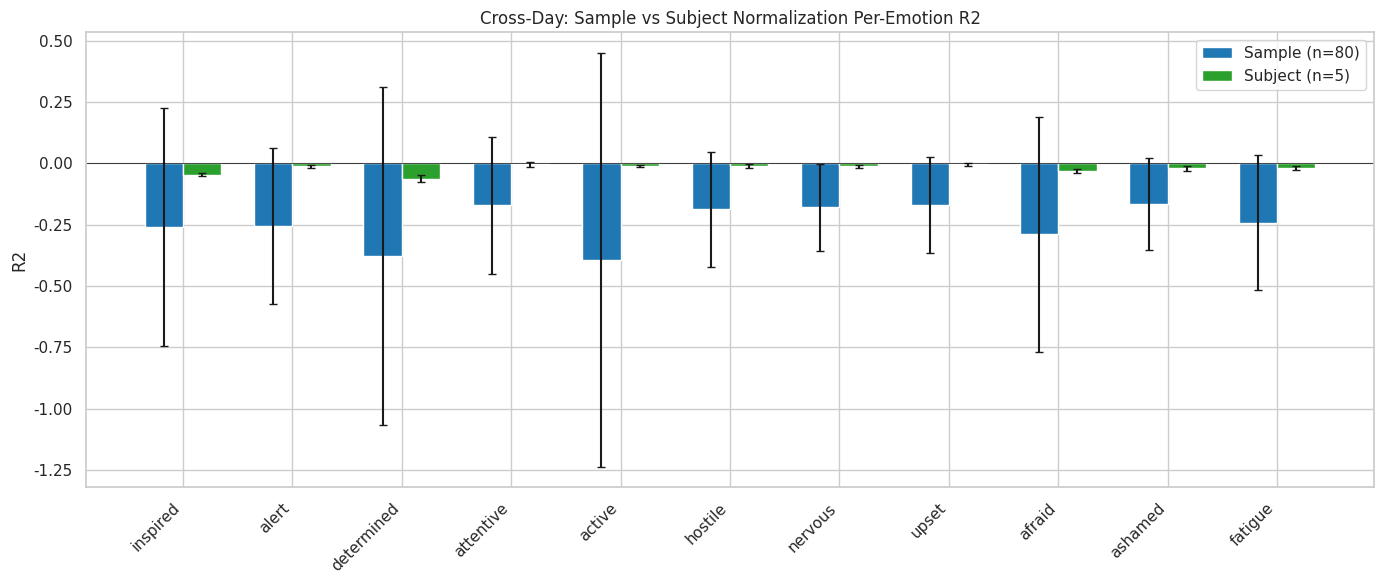

In [23]:
if cd_samp_df is not None and cd_sub_df is not None:
    fig, ax = plt.subplots(figsize=(14, 6))
    x = np.arange(len(EMOTIONS))
    w = 0.35
    s_means = cd_samp_df.set_index('Emotion')['R2_mean'].reindex(EMOTIONS).values
    s_stds = cd_samp_df.set_index('Emotion')['R2_std'].reindex(EMOTIONS).values
    u_means = cd_sub_df.set_index('Emotion')['R2_mean'].reindex(EMOTIONS).values
    u_stds = cd_sub_df.set_index('Emotion')['R2_std'].reindex(EMOTIONS).values

    ax.bar(x - w/2, s_means, w, yerr=s_stds, label='Sample (n=80)', color='#1f77b4', capsize=3)
    ax.bar(x + w/2, u_means, w, yerr=u_stds, label='Subject (n=5)', color='#2ca02c', capsize=3)
    ax.set_xticks(x)
    ax.set_xticklabels(EMOTIONS, rotation=45, ha='right')
    ax.set_ylabel('R2')
    ax.set_title('Cross-Day: Sample vs Subject Normalization Per-Emotion R2')
    ax.axhline(y=0, color='black', linewidth=0.5)
    ax.legend()
    plt.tight_layout()
    plt.show()

### 2.4 标准化策略改进幅度热力图 (ΔR²)

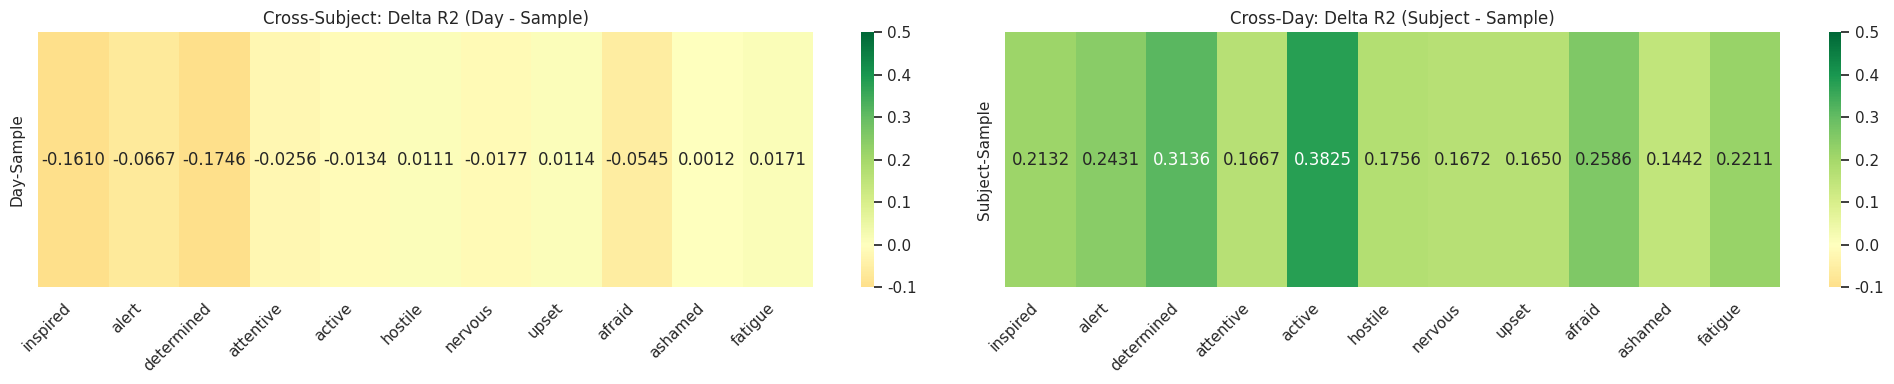

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(20, 4))

# Cross-Subject: Day - Sample
if cs_samp_df is not None and cs_day_df is not None:
    delta = (cs_day_df.set_index('Emotion')['R2_mean'] -
             cs_samp_df.set_index('Emotion')['R2_mean']).reindex(EMOTIONS).values.reshape(1, -1)
    sns.heatmap(delta, annot=True, fmt='.4f', cmap='RdYlGn', center=0,
                xticklabels=EMOTIONS, yticklabels=['Day-Sample'],
                ax=axes[0], vmin=-0.1, vmax=0.5)
    axes[0].set_title('Cross-Subject: Delta R2 (Day - Sample)')
    axes[0].set_xticklabels(EMOTIONS, rotation=45, ha='right')

# Cross-Day: Subject - Sample
if cd_samp_df is not None and cd_sub_df is not None:
    delta = (cd_sub_df.set_index('Emotion')['R2_mean'] -
             cd_samp_df.set_index('Emotion')['R2_mean']).reindex(EMOTIONS).values.reshape(1, -1)
    sns.heatmap(delta, annot=True, fmt='.4f', cmap='RdYlGn', center=0,
                xticklabels=EMOTIONS, yticklabels=['Subject-Sample'],
                ax=axes[1], vmin=-0.1, vmax=0.5)
    axes[1].set_title('Cross-Day: Delta R2 (Subject - Sample)')
    axes[1].set_xticklabels(EMOTIONS, rotation=45, ha='right')

plt.tight_layout()
plt.show()

## 3. 显著性检验

### 3.1 Cross-Subject: Sample vs Day (配对 t 检验，按情绪配对)

In [25]:
print('Cross-Subject: Sample vs Day Normalization Significance Test (n=5 seeds)')
print('-' * 70)
if cs_samp_df is not None and cs_day_df is not None:
    print(f"{'Emotion':<12} {'t-stat':>10} {'p-value':>12} {'sig':>6}")
    print('-' * 70)
    for em in EMOTIONS:
        s_vals = [e['per_emotion'][em]['R2'] for e in cs_sample if em in e.get('per_emotion',{})]
        d_vals = [e['per_emotion'][em]['R2'] for e in cs_day if em in e.get('per_emotion',{})]
        if len(s_vals) >= 2 and len(d_vals) >= 2:
            t, p = stats.ttest_ind(s_vals, d_vals, equal_var=False)
            sig = '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
            print(f"{em:<12} {t:>10.3f} {p:>12.4f} {sig:>6}")

print()
print('Cross-Day: Sample vs Subject Normalization Significance Test')
print('(Note: Sample n=80, Subject n=5, large sample size difference)')
print('-' * 70)
if cd_samp_df is not None and cd_sub_df is not None:
    print(f"{'Emotion':<12} {'t-stat':>10} {'p-value':>12} {'sig':>6}")
    print('-' * 70)
    for em in EMOTIONS:
        s_vals = [e['per_emotion'][em]['R2'] for e in cd_sample if em in e.get('per_emotion',{})]
        u_vals = [e['per_emotion'][em]['R2'] for e in sub_std_exps if em in e.get('per_emotion',{})]
        if len(s_vals) >= 2 and len(u_vals) >= 2:
            t, p = stats.ttest_ind(s_vals, u_vals, equal_var=False)
            sig = '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
            print(f"{em:<12} {t:>10.3f} {p:>12.4f} {sig:>6}")

Cross-Subject: Sample vs Day Normalization Significance Test (n=5 seeds)
----------------------------------------------------------------------
Emotion          t-stat      p-value    sig
----------------------------------------------------------------------
inspired         -0.822       0.4301     ns
alert            -0.606       0.5578     ns
determined       -1.166       0.2663     ns
attentive        -0.929       0.3753     ns
active           -1.682       0.1172     ns
hostile          -1.501       0.1847     ns
nervous          -1.049       0.3205     ns
upset            -0.625       0.5644     ns
afraid           -0.722       0.4903     ns
ashamed           0.328       0.7566     ns
fatigue           0.229       0.8274     ns

Cross-Day: Sample vs Subject Normalization Significance Test
(Note: Sample n=80, Subject n=5, large sample size difference)
----------------------------------------------------------------------
Emotion          t-stat      p-value    sig
-----------------

## 4. 实验元信息

| 实验名称 | split_mode | norm_mode | 结果目录 | n_seeds |
|----------|-----------|-----------|----------|---------|
| cross_subject (sample) | cross_subject | sample | `results4/` | 5 |
| cross_subject (day) | cross_subject | day | `result_day_td/` | 5 |
| cross_day (sample) | cross_day | sample | `results4/` | 80 (15 subj × 5+) |
| cross_day (subject) | cross_day | subject | `result_sub_std/` | 5 |
| within_subject_day (sample) | within_subject_day | sample | `results4/` | 5 |

### 关键发现

1. **Cross-Subject (Day norm)**:
   - 整体 R² 略降 (0.108 → 0.093)，但 per-emotion R² 大幅改善
   - `inspired` R²: -0.408 → -0.003 (Δ=+0.405)
   - `determined` R²: -0.570 → -0.110 (Δ=+0.460)
   - `afraid` R²: -0.161 → -0.015 (Δ=+0.146)
   - 仅 `upset`, `ashamed`, `fatigue` 略有下降

2. **Cross-Day (Subject norm)**:
   - 整体 R² 略升 (0.169 → 0.177)
   - `test_avg_r2` 大幅改善 (-0.321 → -0.015)
   - 所有 11 个情绪维度 R² 均改善
   - `active` R²: -0.394 → -0.011 (Δ=+0.383)
   - `determined` R²: -0.377 → -0.064 (Δ=+0.314)
   - 注意：Subject norm 只有 5 个 seed（all subjects pooled），方差更小

In [26]:
dtl = df.copy()
if 'timestamp' not in dtl.columns:
    dtl['timestamp'] = [e.get('directory','').split('_')[0] if '_' in e.get('directory','') else '' for e in all_exps]
cols = [c for c in ['timestamp','split_mode','norm_mode','target_subject','n_source_domains',
          'best_epoch','test_mse','test_mae','test_r2','test_pearson','test_spearman','directory'] if c in dtl.columns]
dtl = dtl[cols].sort_values([c for c in ['split_mode','norm_mode','target_subject','timestamp'] if c in dtl.columns])
print(f'All experiments ({len(dtl)} total):')
print(dtl.to_string(index=False))


All experiments (105 total):
timestamp         split_mode norm_mode target_subject  n_source_domains  best_epoch  test_mse  test_mae   test_r2  test_pearson  test_spearman                                  directory
 20260803          cross_day       day            all                90         244  0.842073  0.721953  0.177145      0.151164       0.134590          20260803_091510_emotion_cross_day
 20260803          cross_day       day            all                90           8  0.840276  0.721313  0.178902      0.088731       0.130172          20260803_091612_emotion_cross_day
 20260803          cross_day       day            all                90          11  0.840551  0.722962  0.178633      0.070414       0.068626          20260803_150055_emotion_cross_day
 20260803          cross_day       day            all                90         172  0.839967  0.723479  0.179203      0.166242       0.127527          20260803_150135_emotion_cross_day
 20260803          cross_day       day   